# IMDB Sentiment Analysis - Complete Enhanced Pipeline
This notebook covers: Text Cleaning → TF-IDF → Multiple Models → Hyperparameter Tuning → Evaluation → Feature Importance → Model Saving → Prediction Function

## 1. Import All Required Libraries

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn nltk joblib

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.




[notice] A new release of pip is available: 26.0.1 -> 26.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
import joblib
import warnings
warnings.filterwarnings('ignore')

# Sklearn - Preprocessing & Splitting
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, learning_curve
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

# Sklearn - Models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier

# Sklearn - Metrics
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, precision_recall_curve, auc
)

# NLTK for text preprocessing
import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

print('All libraries imported successfully!')

All libraries imported successfully!


## 2. Load Dataset

In [3]:
df = pd.read_csv('IMDB Dataset.csv')
print('Shape:', df.shape)
print('\nClass Distribution:')
print(df['sentiment'].value_counts())
df.head(5)

Shape: (50000, 2)

Class Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 3. Text Cleaning & Preprocessing

In [4]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """Full text cleaning pipeline."""
    # 1. Remove HTML tags (common in IMDB reviews)
    text = re.sub(r'<.*?>', ' ', text)
    # 2. Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    # 3. Lowercase
    text = text.lower()
    # 4. Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)
    # 5. Tokenize
    tokens = text.split()
    # 6. Remove stop words and lemmatize
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

print('Cleaning text... (may take a minute)')
df['clean_review'] = df['review'].apply(clean_text)

# Show before/after
print('\nOriginal:')
print(df['review'].iloc[0][:300])
print('\nCleaned:')
print(df['clean_review'].iloc[0][:300])

Cleaning text... (may take a minute)

Original:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru

Cleaned:
one reviewer mentioned watching episode youll hooked right exactly happened first thing struck brutality unflinching scene violence set right word trust show faint hearted timid show pull punch regard drug sex violence hardcore classic use word called nickname given oswald maximum security state pen


## 4. Feature Engineering - Review Length & Extra Features

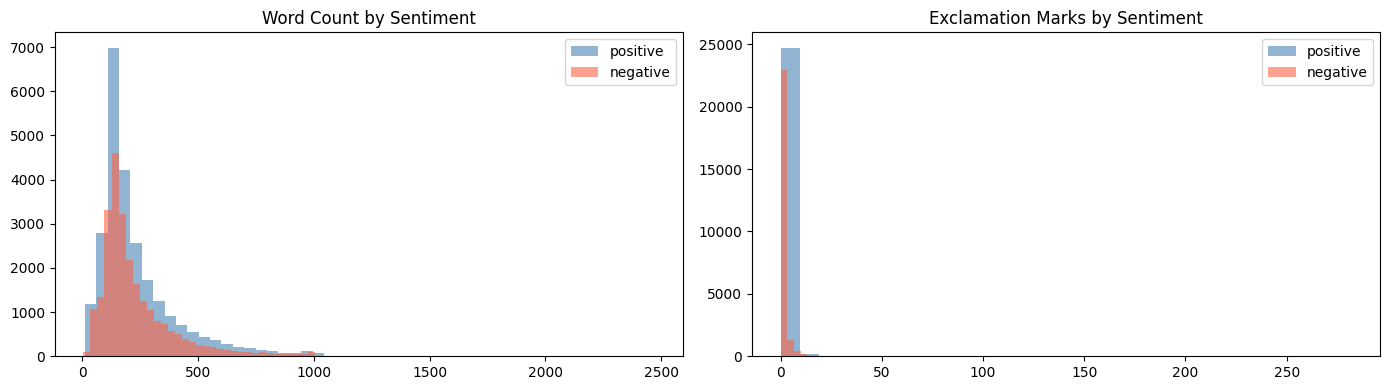

In [11]:
# Add numeric features
df['review_length']     = df['review'].apply(len)
df['word_count']        = df['review'].apply(lambda x: len(x.split()))
df['exclamation_count'] = df['review'].apply(lambda x: x.count('!'))
df['question_count']    = df['review'].apply(lambda x: x.count('?'))

# Visualise length distribution by sentiment
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for sentiment, color in [('positive', 'steelblue'), ('negative', 'tomato')]:
    subset = df[df['sentiment'] == sentiment]
    axes[0].hist(subset['word_count'], bins=50, alpha=0.6, label=sentiment, color=color)
    axes[1].hist(subset['exclamation_count'], bins=30, alpha=0.6, label=sentiment, color=color)
axes[0].set_title('Word Count by Sentiment'); axes[0].legend()
axes[1].set_title('Exclamation Marks by Sentiment'); axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Encode Labels & Split Data

In [12]:
# Encode labels: positive=1, negative=0
le = LabelEncoder()
df['label'] = le.fit_transform(df['sentiment'])  # negative=0, positive=1
print('Label mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

X = df['clean_review']
y = df['label']

# Stratified split to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)
print(f'Train size: {len(X_train)} | Test size: {len(X_test)}')
print(f'Train class balance: {y_train.value_counts().to_dict()}')

Label mapping: {'negative': np.int64(0), 'positive': np.int64(1)}
Train size: 33500 | Test size: 16500
Train class balance: {0: 16750, 1: 16750}


## 6. TF-IDF Vectorization

In [13]:
vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=50000,
    ngram_range=(1, 2),      # unigrams + bigrams
    sublinear_tf=True,       # apply log normalization to TF
    min_df=2                 # ignore very rare terms
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf  = vectorizer.transform(X_test)

print('Train TF-IDF shape:', X_train_tfidf.shape)
print('Test  TF-IDF shape:', X_test_tfidf.shape)

Train TF-IDF shape: (33500, 50000)
Test  TF-IDF shape: (16500, 50000)


## 7. Train Multiple Models & Compare

In [14]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, C=1),
    'Naive Bayes':         MultinomialNB(alpha=0.1),
    'LinearSVC':           LinearSVC(class_weight='balanced', max_iter=2000, C=1),
    'Random Forest':       RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
}

results = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f'{"Model":<25} {"CV Mean":>10} {"CV Std":>10} {"Test Acc":>10}')
print('-' * 60)
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train_tfidf, y_train, cv=skf, scoring='accuracy', n_jobs=-1)
    model.fit(X_train_tfidf, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test_tfidf))
    results[name] = {'model': model, 'cv_mean': cv_scores.mean(), 'cv_std': cv_scores.std(), 'test_acc': test_acc}
    print(f'{name:<25} {cv_scores.mean():>10.4f} {cv_scores.std():>10.4f} {test_acc:>10.4f}')

Model                        CV Mean     CV Std   Test Acc
------------------------------------------------------------
Logistic Regression           0.8910     0.0033     0.8941
Naive Bayes                   0.8742     0.0038     0.8715
LinearSVC                     0.8916     0.0029     0.8964
Random Forest                 0.8542     0.0035     0.8597


## 8. Visualise Model Comparison

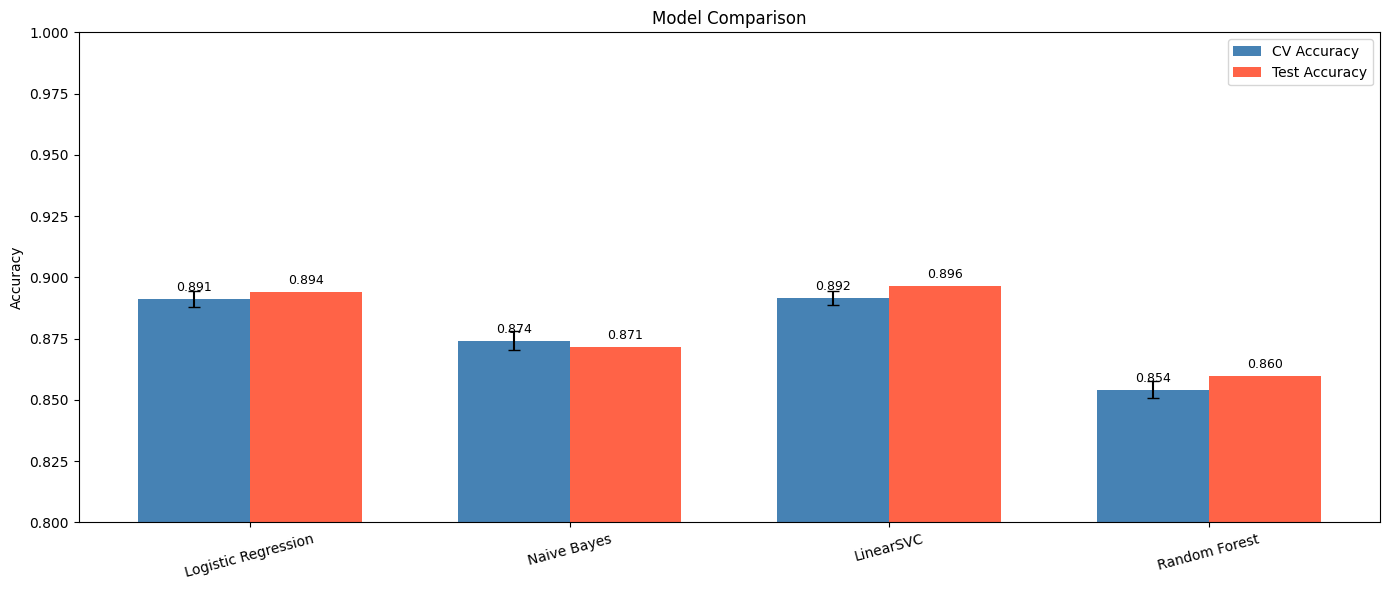

In [17]:
names     = list(results.keys())
cv_means  = [results[n]['cv_mean'] for n in names]
cv_stds   = [results[n]['cv_std']  for n in names]
test_accs = [results[n]['test_acc'] for n in names]

x = np.arange(len(names))
width = 0.35
fig, ax = plt.subplots(figsize=(14, 6))
bars1 = ax.bar(x - width/2, cv_means, width, label='CV Accuracy', color='steelblue', yerr=cv_stds, capsize=4)
bars2 = ax.bar(x + width/2, test_accs, width, label='Test Accuracy', color='tomato')
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15)
ax.set_ylim(0.8, 1.0)
ax.set_ylabel('Accuracy'); ax.set_title('Model Comparison')
ax.legend()
for bar in bars1: ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002, f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2: ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002, f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 9. Hyperparameter Tuning (Best Model - Logistic Regression)

In [16]:
param_grid = {
    'C':       [0.01, 0.1, 1, 10],
    'penalty': ['l2'],
    'solver':  ['liblinear']
}
grid = GridSearchCV(
    LogisticRegression(class_weight='balanced', max_iter=1000),
    param_grid, cv=skf, scoring='accuracy', n_jobs=-1, verbose=1
)
grid.fit(X_train_tfidf, y_train)
best_model = grid.best_estimator_

print("Best Model:", best_model)
print('Best Params:', grid.best_params_)
print('Best CV Score:', round(grid.best_score_, 4))

Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best Model: LogisticRegression(C=10, class_weight='balanced', max_iter=1000,
                   solver='liblinear')
Best Params: {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV Score: 0.8941


## 10. Voting Classifier (Ensemble)

In [18]:
voting_clf = VotingClassifier(
    estimators=[
        ('lr',  LogisticRegression(class_weight='balanced', max_iter=1000, C=1)),
        ('svm', LinearSVC(class_weight='balanced', max_iter=2000, C=1)),
    ],
    voting='hard'
)
voting_clf.fit(X_train_tfidf, y_train)
voting_acc = accuracy_score(y_test, voting_clf.predict(X_test_tfidf))
print(f'Voting Classifier Test Accuracy: {voting_acc:.4f}')

Voting Classifier Test Accuracy: 0.8954


## 11. Detailed Evaluation of Best Model

In [19]:
y_pred      = best_model.predict(X_test_tfidf)
y_pred_prob = best_model.predict_proba(X_test_tfidf)[:, 1]

print('=== Classification Report ===')
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))
print(f'ROC-AUC Score: {roc_auc_score(y_test, y_pred_prob):.4f}')

=== Classification Report ===
              precision    recall  f1-score   support

    Negative       0.90      0.89      0.90      8250
    Positive       0.89      0.91      0.90      8250

    accuracy                           0.90     16500
   macro avg       0.90      0.90      0.90     16500
weighted avg       0.90      0.90      0.90     16500

ROC-AUC Score: 0.9626


## 12. Confusion Matrix

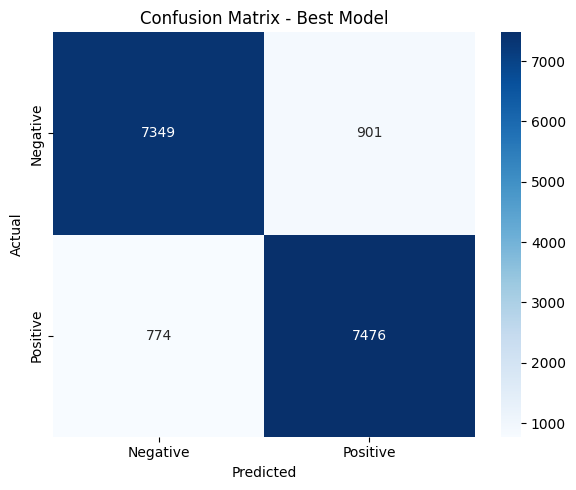

In [20]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix - Best Model')
plt.tight_layout()
plt.show()

## 13. ROC Curve

The predicted Probabilities: [3.66128999e-02 7.45430483e-01 1.36245045e-01 ... 5.96426481e-04
 5.86451023e-01 9.93320405e-01]


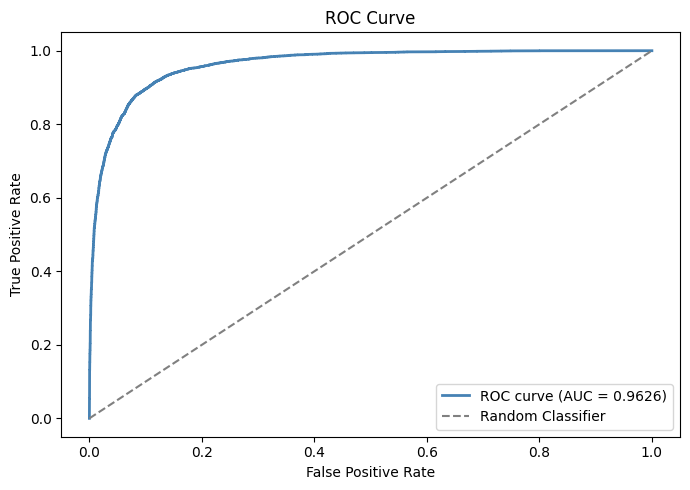

In [25]:
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
roc_auc     = auc(fpr, tpr)

print("The predicted Probabilities:" ,y_pred_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='steelblue', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend()
plt.tight_layout()
plt.show()

## 14. Precision-Recall Curve

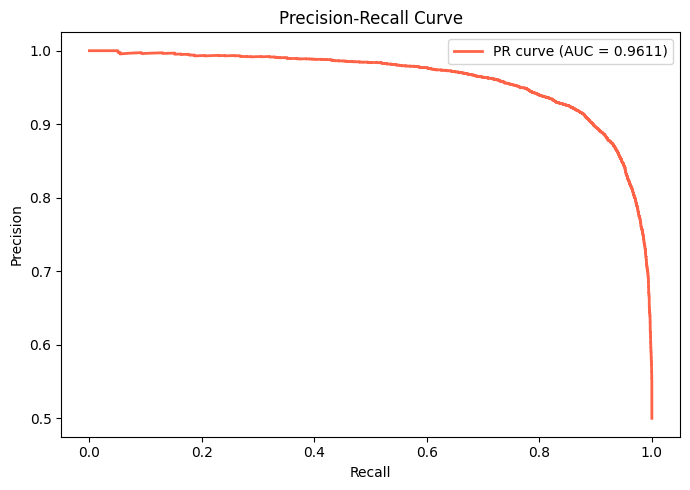

In [26]:
precision, recall, _ = precision_recall_curve(y_test, y_pred_prob)
pr_auc = auc(recall, precision)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, color='tomato', lw=2, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall Curve'); plt.legend()
plt.tight_layout()
plt.show()

## 15. Learning Curves (Overfitting Check)

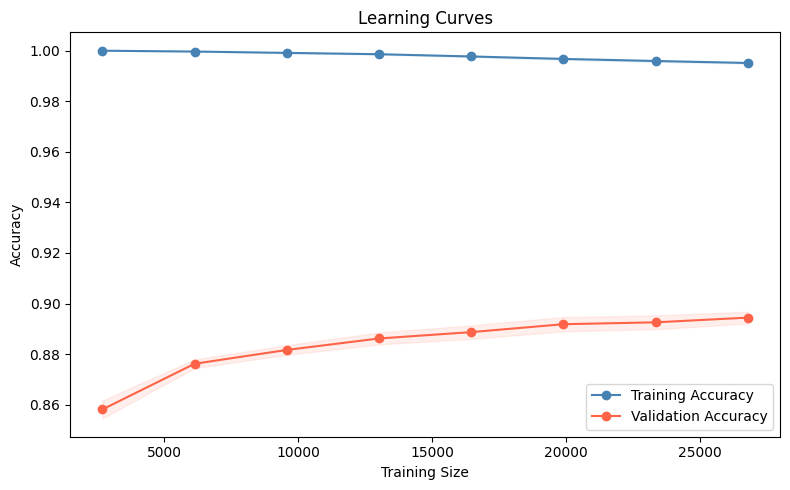

In [27]:
train_sizes, train_scores, val_scores = learning_curve(
    best_model, X_train_tfidf, y_train,
    cv=5, scoring='accuracy', n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 8)
)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', color='steelblue', label='Training Accuracy')
plt.fill_between(train_sizes,
                 train_scores.mean(axis=1) - train_scores.std(axis=1),
                 train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1, color='steelblue')
plt.plot(train_sizes, val_scores.mean(axis=1), 'o-', color='tomato', label='Validation Accuracy')
plt.fill_between(train_sizes,
                 val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.1, color='tomato')
plt.xlabel('Training Size'); plt.ylabel('Accuracy')
plt.title('Learning Curves'); plt.legend()
plt.tight_layout()
plt.show()

## 16. Feature Importance — Top Words for Each Sentiment

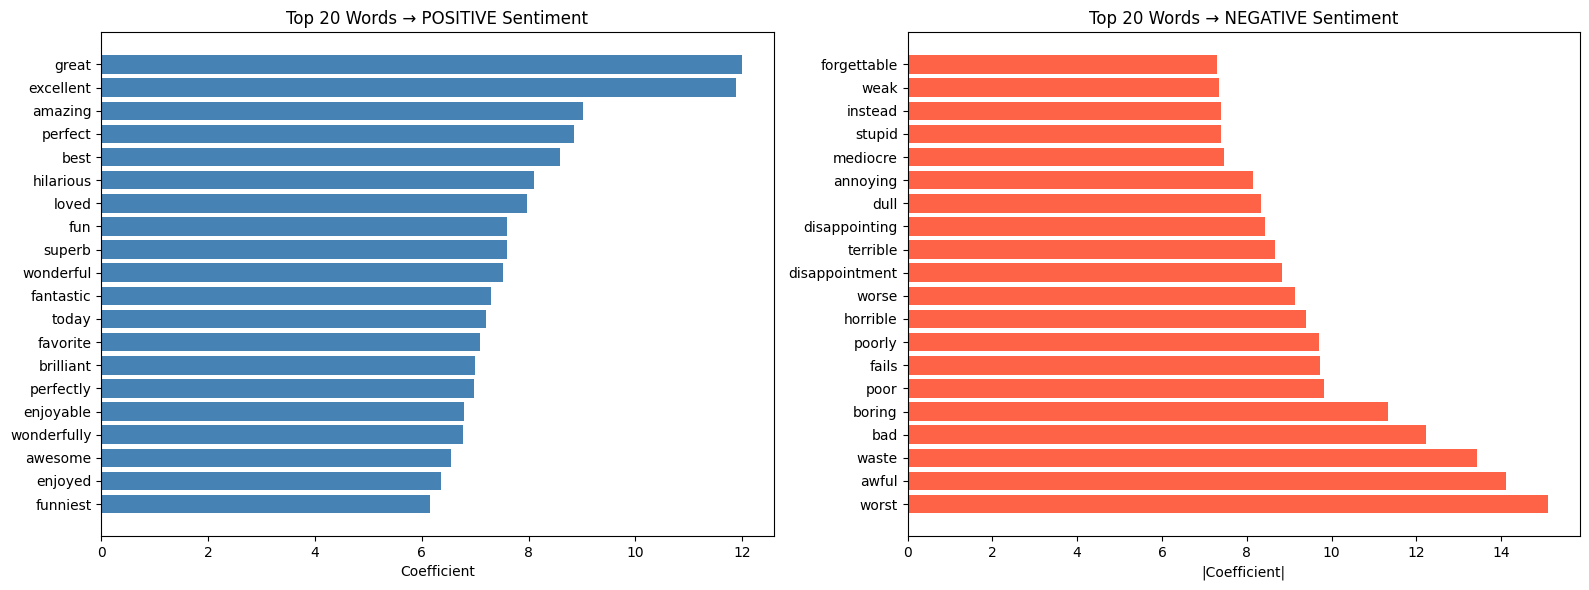

In [17]:
feature_names = np.array(vectorizer.get_feature_names_out())
coef = best_model.coef_[0]
top_n = 20

top_positive_idx = coef.argsort()[-top_n:][::-1]
top_negative_idx = coef.argsort()[:top_n]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Positive features
axes[0].barh(feature_names[top_positive_idx][::-1], coef[top_positive_idx][::-1], color='steelblue')
axes[0].set_title('Top 20 Words → POSITIVE Sentiment')
axes[0].set_xlabel('Coefficient')

# Negative features
axes[1].barh(feature_names[top_negative_idx], np.abs(coef[top_negative_idx]), color='tomato')
axes[1].set_title('Top 20 Words → NEGATIVE Sentiment')
axes[1].set_xlabel('|Coefficient|')

plt.tight_layout()
plt.show()

## 17. Save Model & Vectorizer

In [18]:
joblib.dump(best_model, 'sentiment_model.pkl')
joblib.dump(vectorizer, 'tfidf_vectorizer.pkl')
joblib.dump(le, 'label_encoder.pkl')
print('Model, vectorizer, and label encoder saved!')

Model, vectorizer, and label encoder saved!


## 18. Reusable Prediction Function

In [19]:
def predict_sentiment(text, model=best_model, vec=vectorizer, encoder=le):
    """
    Predict sentiment for a raw review string.
    Returns: label string and confidence score.
    """
    cleaned   = clean_text(text)
    tfidf_vec = vec.transform([cleaned])
    pred      = model.predict(tfidf_vec)[0]
    prob      = model.predict_proba(tfidf_vec)[0][pred]
    label     = encoder.inverse_transform([pred])[0]
    return label, round(prob * 100, 2)

# --- Test it ---
test_reviews = [
    "This movie was absolutely fantastic! One of the best films I've ever seen.",
    "Terrible film. Waste of time. The acting was horrible and the plot made no sense.",
    "It was an okay movie. Nothing special but not terrible either."
]

print('=== Prediction Examples ===')
for review in test_reviews:
    label, confidence = predict_sentiment(review)
    print(f'Review : {review[:80]}...')
    print(f'Verdict: {label.upper()} ({confidence}% confidence)')
    print()

=== Prediction Examples ===
Review : This movie was absolutely fantastic! One of the best films I've ever seen....
Verdict: POSITIVE (98.91% confidence)

Review : Terrible film. Waste of time. The acting was horrible and the plot made no sense...
Verdict: NEGATIVE (100.0% confidence)

Review : It was an okay movie. Nothing special but not terrible either....
Verdict: NEGATIVE (98.84% confidence)



## 19. Final Summary

In [20]:
print('=' * 55)
print('         IMDB SENTIMENT ANALYSIS - FINAL SUMMARY')
print('=' * 55)
print(f'Dataset Size       : {len(df):,} reviews')
print(f'Vocabulary Size    : {len(vectorizer.vocabulary_):,} features')
print(f'Train / Test Split : 67% / 33% (stratified)')
print()
print('Model Performances:')
for name, res in results.items():
    print(f'  {name:<25} CV={res["cv_mean"]:.4f}  Test={res["test_acc"]:.4f}')
print(f'  {"Voting Classifier":<25} Test={voting_acc:.4f}')
print()
print(f'Best Model         : Logistic Regression (GridSearchCV tuned)')
print(f'Best Test Accuracy : {accuracy_score(y_test, y_pred):.4f}')
print(f'ROC-AUC Score      : {roc_auc_score(y_test, y_pred_prob):.4f}')
print('=' * 55)

         IMDB SENTIMENT ANALYSIS - FINAL SUMMARY
Dataset Size       : 50,000 reviews
Vocabulary Size    : 50,000 features
Train / Test Split : 67% / 33% (stratified)

Model Performances:
  Logistic Regression       CV=0.8910  Test=0.8941
  Naive Bayes               CV=0.8742  Test=0.8715
  LinearSVC                 CV=0.8916  Test=0.8964
  Random Forest             CV=0.8542  Test=0.8597
  Voting Classifier         Test=0.8954

Best Model         : Logistic Regression (GridSearchCV tuned)
Best Test Accuracy : 0.8985
ROC-AUC Score      : 0.9626
